| Inicio | Anterior | Siguiente |
| --- | --- | --- |
| [🏠](../README.md) | [⏪](../21_MATEMATICA_MAS_AVANZADA/21_1_Analisis_real.ipynb) | [⏩](../21_MATEMATICA_MAS_AVANZADA/21_3_PDE_avanzada.ipynb) |

# 21.2 ANÁLISIS FUNCIONAL

El análisis funcional extiende ideas de álgebra lineal a espacios cuyos elementos pueden ser funciones y cuyos operadores pueden ser derivadas, integrales o soluciones de PDEs. En SciML resulta natural: un neural operator recibe una función y devuelve otra; una solución débil se busca en un espacio con una norma; un problema inverso intenta invertir un operador que puede ser inestable.

Usaremos ejemplos de normas, proyecciones de Fourier, difusión y regularización. El código trabaja con discretizaciones finitas; las propiedades infinitodimensionales se explicarán mediante definiciones y fórmulas, sin confundir una matriz con el objeto continuo completo.

**Objetivos.** Distinguir Banach y Hilbert, entender operadores acotados, conectar compacidad con problemas inversos y formular una solución variacional. Bibliotecas: NumPy, SciPy y Matplotlib. Requisitos: análisis real, matrices y Fourier.

## 1. Espacios normados y completitud

Un espacio normado tiene una función $\|\cdot\|$ con positividad, homogeneidad y desigualdad triangular. La norma induce distancia. Un **Banach** es completo en esa distancia: toda sucesión de Cauchy tiene límite dentro del espacio.

Un **Hilbert** es completo y su norma proviene de un producto interno, $\|u\|^2=\langle u,u\rangle$. En $L^2(0,1)$,
$$\langle u,v\rangle=\int_0^1u(x)v(x)\,dx.$$
Los elementos de $L^2$ son clases de funciones iguales casi en todas partes, así que modificar un punto no crea un elemento distinto. Esta precisión evita tratar evaluación puntual como una operación siempre bien definida.

## 2. Normas de funciones y escalamiento de malla

Para $1\le p<\infty$, $\|u\|_{L^p}=(\int|u|^p)^{1/p}$; $L^\infty$ usa supremo esencial. Una norma vectorial sobre valores de malla no es automáticamente una norma de función: para malla uniforme necesitamos peso $h$ en $\|u\|_{L^2}\approx\sqrt{h\sum_i u_i^2}$.

En dimensión finita las normas son equivalentes, pero sus constantes pueden depender de dimensión: $\|z\|_\infty\le\|z\|_2\le\sqrt N\|z\|_\infty$. Si refinamos la malla, ignorar esa dependencia puede cambiar pérdidas y métricas aunque la función sea la misma.

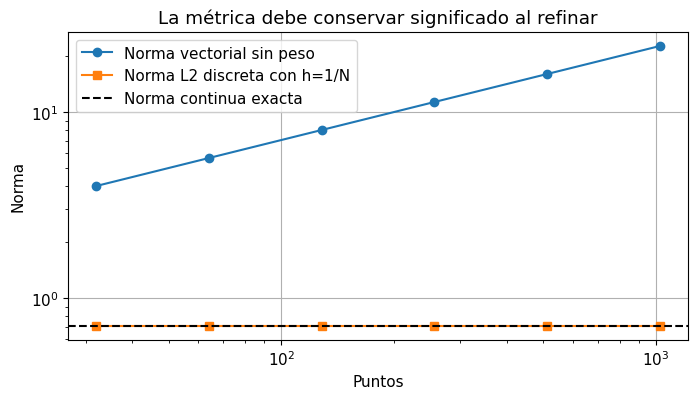

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import trapezoid
plt.rcParams.update({"figure.figsize": (8, 4), "axes.grid": True, "font.size": 11})
ns = np.array([32, 64, 128, 256, 512, 1024])
norma_vector, norma_funcion = [], []
for n in ns:
    x = (np.arange(n)+0.5)/n
    f = np.sin(np.pi*x)
    norma_vector.append(np.linalg.norm(f))
    norma_funcion.append(np.sqrt(np.mean(f*f)))
fig, ax = plt.subplots()
ax.loglog(ns, norma_vector, "o-", label="Norma vectorial sin peso")
ax.loglog(ns, norma_funcion, "s-", label="Norma L2 discreta con h=1/N")
ax.axhline(1/np.sqrt(2), color="k", ls="--", label="Norma continua exacta")
ax.set(xlabel="Puntos", ylabel="Norma", title="La métrica debe conservar significado al refinar")
ax.legend(); plt.show()

## 3. Ortogonalidad y proyección

Las funciones $\phi_m(x)=\sqrt2\sin(m\pi x)$ forman una base ortonormal de $L^2(0,1)$. La proyección en los primeros $M$ modos es
$$P_Mf=\sum_{m=1}^M\langle f,\phi_m\rangle\phi_m.$$
El error es ortogonal al subespacio, por lo que $\|f\|^2=\|P_Mf\|^2+\|f-P_Mf\|^2$. También es la mejor aproximación en norma $L^2$ dentro de ese subespacio.

Esta idea explica Galerkin y reducción de orden: elegir un espacio pequeño y proyectar. En POD, la base se obtiene de datos y una métrica; si cambian pesos espaciales, cambia qué significa capturar «energía».

Diferencia en identidad de Pitágoras: -5.268963154439455e-17


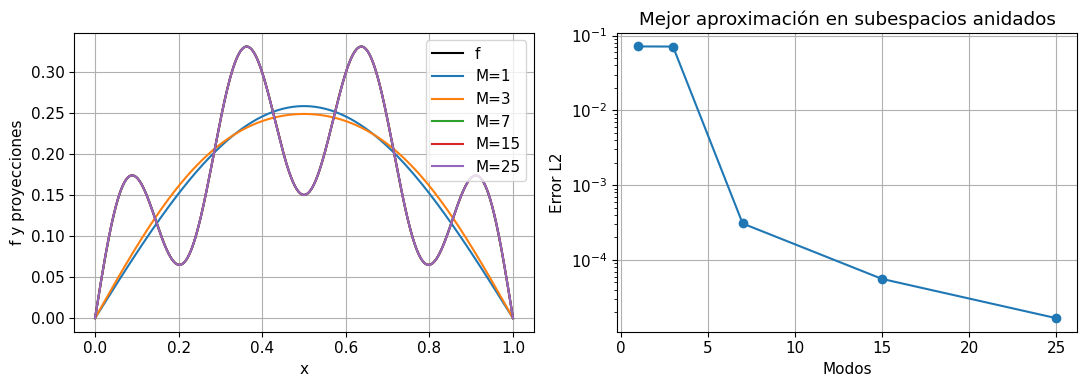

In [2]:
x = np.linspace(0, 1, 3001)
Mmax = 25
m = np.arange(1, Mmax+1)
Phi = np.sqrt(2)*np.sin(np.pi*x[:, None]*m[None, :])
f = x*(1-x)+0.1*np.sin(7*np.pi*x)
coef = trapezoid(f[:, None]*Phi, x, axis=0)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(x, f, "k", label="f")
errors = []
for M in [1, 3, 7, 15, 25]:
    proy = Phi[:, :M] @ coef[:M]
    errors.append(np.sqrt(trapezoid((f-proy)**2, x)))
    axes[0].plot(x, proy, label=f"M={M}")
axes[0].set(xlabel="x", ylabel="f y proyecciones"); axes[0].legend()
axes[1].semilogy([1, 3, 7, 15, 25], errors, "o-")
axes[1].set(xlabel="Modos", ylabel="Error L2", title="Mejor aproximación en subespacios anidados")
plt.tight_layout(); plt.show()
M = 7; proy = Phi[:, :M] @ coef[:M]
print("Diferencia en identidad de Pitágoras:", trapezoid(f*f, x)-trapezoid(proy*proy, x)-trapezoid((f-proy)**2, x))

## 4. Operadores lineales acotados

Un operador $T:X\to Y$ es lineal si respeta combinaciones lineales. Es acotado si existe $C$ tal que $\|Tu\|_Y\le C\|u\|_X$; para operadores lineales eso equivale a continuidad. Su norma es el menor $C$, o $\sup_{\|u\|=1}\|Tu\|$.

Derivar no es un operador acotado de $L^2$ a $L^2$: para $\phi_m$, la norma inicial es uno y $\|\phi_m'\|_{L^2}=m\pi$. En cambio, derivar de $H^1$ a $L^2$ sí es acotado porque la norma $H^1$ incluye la derivada.

Un operador puede ser estable en un espacio y no en otro. Por eso frases como «el solver es continuo» o «la red aproxima bien» deben indicar dominio, codominio y normas.

## 5. Espacios de Sobolev y derivadas débiles

$H^1(0,1)$ contiene funciones de $L^2$ cuya derivada débil también está en $L^2$. Una derivada débil $v$ satisface
$$\int_0^1u\varphi'\,dx=-\int_0^1v\varphi\,dx$$
para funciones de prueba suaves con soporte interior. La norma es $\|u\|_{H^1}^2=\|u\|_{L^2}^2+\|u'\|_{L^2}^2$.

$u(x)=|x-1/2|$ no tiene derivada clásica en el centro, pero tiene derivada débil $\operatorname{sign}(x-1/2)$ en $L^2$. Su segunda derivada distribucional es una delta multiplicada por dos y no está en $L^2$, así que no pertenece a $H^2$.

Integral u·psi' y -v·psi: 0.005208325231484056 0.005208332175925411


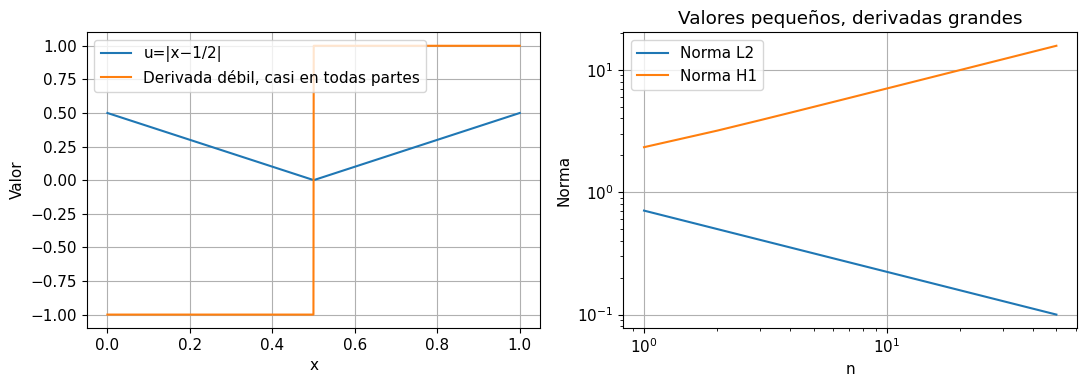

In [3]:
u = np.abs(x-0.5)
v = np.sign(x-0.5)
# Prueba suave con valor cero en extremos; ilustra integración por partes.
psi = x*x*(1-x)**3
dpsi = 2*x*(1-x)**3-3*x*x*(1-x)**2
izq = trapezoid(u*dpsi, x); der = -trapezoid(v*psi, x)
print("Integral u·psi' y -v·psi:", izq, der)
assert np.isclose(izq, der, atol=5e-7)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(x, u, label="u=|x−1/2|")
axes[0].plot(x, v, label="Derivada débil, casi en todas partes")
axes[0].set(xlabel="x", ylabel="Valor"); axes[0].legend()
ns = np.arange(1, 51)
# f_n = sin(nπx)/sqrt(n): L2 → 0, H1 crece.
l2 = 1/np.sqrt(2*ns)
h1 = np.sqrt(1/(2*ns)+(np.pi**2*ns)/2)
axes[1].loglog(ns, l2, label="Norma L2")
axes[1].loglog(ns, h1, label="Norma H1")
axes[1].set(xlabel="n", ylabel="Norma", title="Valores pequeños, derivadas grandes")
axes[1].legend(); plt.tight_layout(); plt.show()

## 6. Funcionales y evaluación puntual

Un funcional lineal asigna un número a una función. En un Hilbert, todo funcional lineal continuo puede representarse como $\ell(u)=\langle u,g\rangle$ para algún $g$; es el teorema de representación de Riesz.

Evaluar $u(x_*)$ no está bien definido sobre clases $L^2$ y no tiene una cota por norma $L^2$. Incluso con funciones continuas, picos estrechos pueden tener norma pequeña y altura grande. En 1D, $H^1$ admite un representante continuo y controla evaluaciones puntuales mediante una desigualdad apropiada. Esa regularidad explica cuándo una observación de sensor tiene sentido como funcional sobre el espacio elegido.

## 7. Convergencia débil y fuerte

Convergencia fuerte significa $\|u_n-u\|\to0$. Convergencia débil significa $\langle u_n,g\rangle\to\langle u,g\rangle$ para toda función de prueba fija $g$ del Hilbert.

Los modos $\phi_n=\sqrt2\sin(n\pi x)$ convergen débilmente a cero, porque sus coeficientes frente a cualquier $g\in L^2$ tienden a cero, pero no fuertemente: su norma siempre es uno. Para la prueba concreta $g=x$,
$$\langle\phi_n,x\rangle=\frac{\sqrt2(-1)^{n+1}}{n\pi}\to0.$$
Una sola función de prueba no demuestra convergencia débil; la base ortonormal y sumabilidad cuadrática de coeficientes justifican el resultado general.

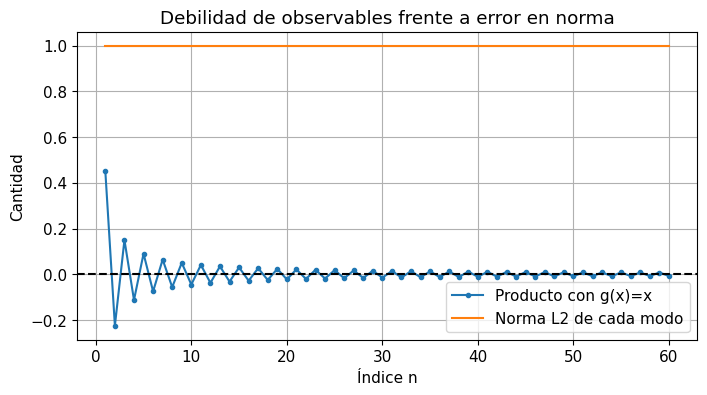

In [4]:
ns = np.arange(1, 61)
coef_prueba = np.sqrt(2)*(-1.0)**(ns+1)/(ns*np.pi)
fig, ax = plt.subplots()
ax.plot(ns, coef_prueba, "o-", ms=3, label="Producto con g(x)=x")
ax.plot(ns, np.ones_like(ns), label="Norma L2 de cada modo")
ax.axhline(0, color="k", ls="--")
ax.set(xlabel="Índice n", ylabel="Cantidad", title="Debilidad de observables frente a error en norma")
ax.legend(); plt.show()

## 8. Compacidad y suavizado por difusión

Para calor con frontera cero, el operador que lleva una condición inicial a tiempo $t>0$ es
$$Tf=\sum_{m=1}^\infty s_m f_m\phi_m,\quad s_m=e^{-\alpha(m\pi)^2t}.$$
Es lineal, acotado y compacto en $L^2$: sus valores singulares tienden a cero, y truncar a un número finito de modos lo aproxima en norma de operador. Para $t=0$ es la identidad, que no es compacta en un Hilbert infinitodimensional.

La compacidad expresa pérdida de información de alta frecuencia. Es útil para existencia y aproximación, pero también señala que invertir difusión puede amplificar brutalmente ruido. En dimensión finita toda matriz tiene propiedades distintas: para estudiar el límite hay que observar qué pasa al aumentar modos.

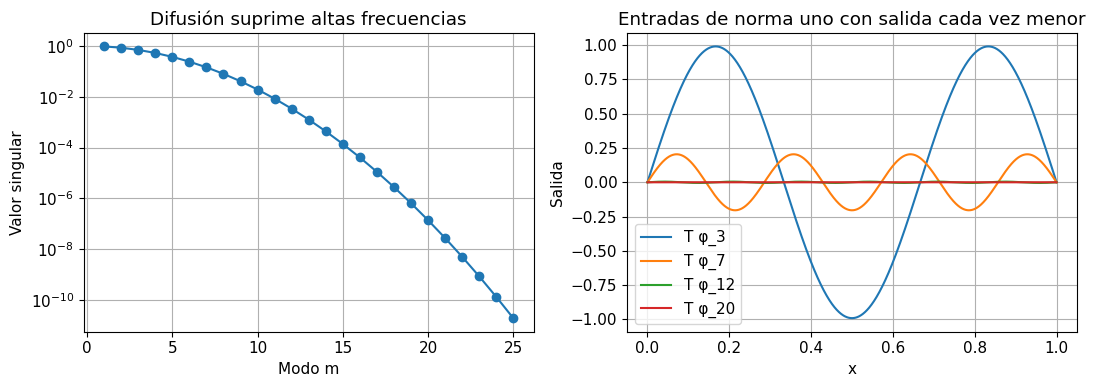

In [5]:
alpha, tiempo = 0.04, 0.1
s = np.exp(-alpha*(np.pi*m)**2*tiempo)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].semilogy(m, s, "o-")
axes[0].set(xlabel="Modo m", ylabel="Valor singular", title="Difusión suprime altas frecuencias")
for M in [3, 7, 12, 20]:
    entrada = Phi[:, M-1]
    axes[1].plot(x, s[M-1]*entrada, label=f"T φ_{M}")
axes[1].set(xlabel="x", ylabel="Salida", title="Entradas de norma uno con salida cada vez menor")
axes[1].legend(); plt.tight_layout(); plt.show()

## 9. Problema inverso y regularización

Si observamos coeficientes $y_m=s_mf_m+\eta_m$, la inversión directa $f_m=y_m/s_m$ amplifica ruido por $1/s_m$. No hay un inverso continuo sobre todo $L^2$ para este operador compacto con valores singulares que se acercan a cero.

Tikhonov minimiza $\|Tf-y\|^2+\lambda\|f\|^2$ y da
$$\widehat f_m=\frac{s_m}{s_m^2+\lambda}y_m.$$
El parámetro equilibra sesgo y amplificación. Elegirlo necesita información sobre ruido o validación; en el siguiente ejemplo podemos comparar con la verdad solo porque es sintético. No usaríamos esa verdad oculta para elegir un parámetro en una aplicación real.

Error L2 por coeficientes, inverso directo: 86554063.87345265
Error L2 por coeficientes, Tikhonov: 0.20060053231570021


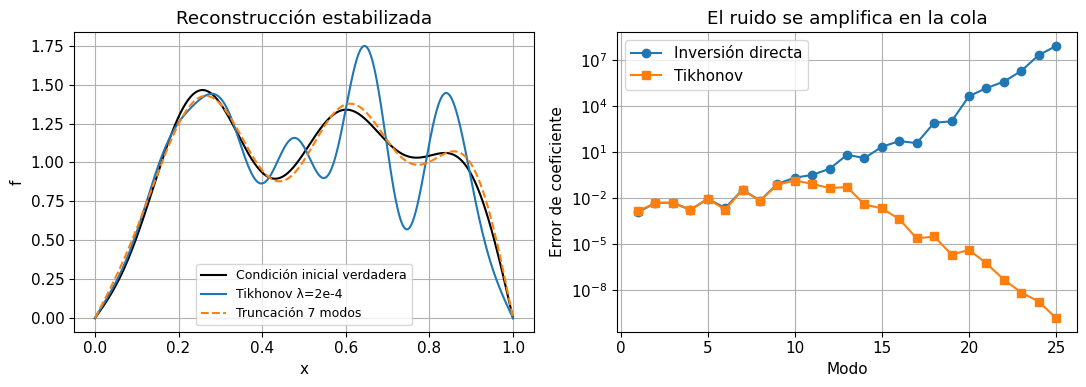

In [6]:
rr = np.random.default_rng(212)
fcoef = np.zeros(Mmax); fcoef[0], fcoef[2], fcoef[5] = 1.0, 0.25, -0.15
sigma = 0.003
ycoef = s*fcoef+rr.normal(0, sigma, Mmax)
inverso_directo = ycoef/s
lambda_reg = 2e-4
f_reg = s*ycoef/(s*s+lambda_reg)
f_trunc = np.zeros(Mmax); f_trunc[:7] = ycoef[:7]/s[:7]
f_verdad = Phi @ fcoef
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(x, f_verdad, "k", label="Condición inicial verdadera")
axes[0].plot(x, Phi @ f_reg, label="Tikhonov λ=2e-4")
axes[0].plot(x, Phi @ f_trunc, "--", label="Truncación 7 modos")
axes[0].set(xlabel="x", ylabel="f", title="Reconstrucción estabilizada"); axes[0].legend(fontsize=9)
axes[1].semilogy(m, np.maximum(np.abs(inverso_directo-fcoef), 1e-15), "o-", label="Inversión directa")
axes[1].semilogy(m, np.maximum(np.abs(f_reg-fcoef), 1e-15), "s-", label="Tikhonov")
axes[1].set(xlabel="Modo", ylabel="Error de coeficiente", title="El ruido se amplifica en la cola")
axes[1].legend(); plt.tight_layout(); plt.show()
print("Error L2 por coeficientes, inverso directo:", np.linalg.norm(inverso_directo-fcoef))
print("Error L2 por coeficientes, Tikhonov:", np.linalg.norm(f_reg-fcoef))

## 10. Forma débil de Poisson y espacio H¹₀

Para $-u''=f$, $u(0)=u(1)=0$, multiplicamos por $v$ y usamos integración por partes:
$$a(u,v)=\int_0^1u'v'\,dx=\int_0^1fv\,dx=\ell(v),\qquad v\in H_0^1(0,1).$$
La condición de frontera se entiende mediante traza; $H_0^1$ es el espacio apropiado. La desigualdad de Poincaré controla $\|u\|_{L^2}$ por $\|u'\|_{L^2}$, así que $a$ es coerciva en ese espacio. Lax–Milgram establece existencia y unicidad cuando $a$ es continua y coerciva y $\ell$ continua.

La energía $J(u)=\frac12a(u,u)-\ell(u)$ se minimiza en la solución. El método de Galerkin busca ese mínimo en un subespacio finito. Si $a$ es simétrica, hay una interpretación de proyección en norma de energía.

## 11. Aproximación de Galerkin y una referencia exacta

Tomemos $f=2$, cuya solución es $u=x(1-x)$. En base seno, $a(\phi_m,\phi_n)=(m\pi)^2\delta_{mn}$ y
$$f_m=\langle2,\phi_m\rangle=\frac{2\sqrt2(1-(-1)^m)}{m\pi},\qquad u_m=\frac{f_m}{(m\pi)^2}.$$
Podemos aproximar con pocos modos y comparar tanto valores como norma de energía. La regularidad de la solución y la base determinan la tasa; no basta con decir que «más parámetros» ayudan.

El lema de Céa da $\|u-u_h\|_V\le(C/\alpha)\inf_{v_h\in V_h}\|u-v_h\|_V$ bajo continuidad $C$ y coercividad $\alpha$. Conecta calidad de la clase de aproximación con error del método.

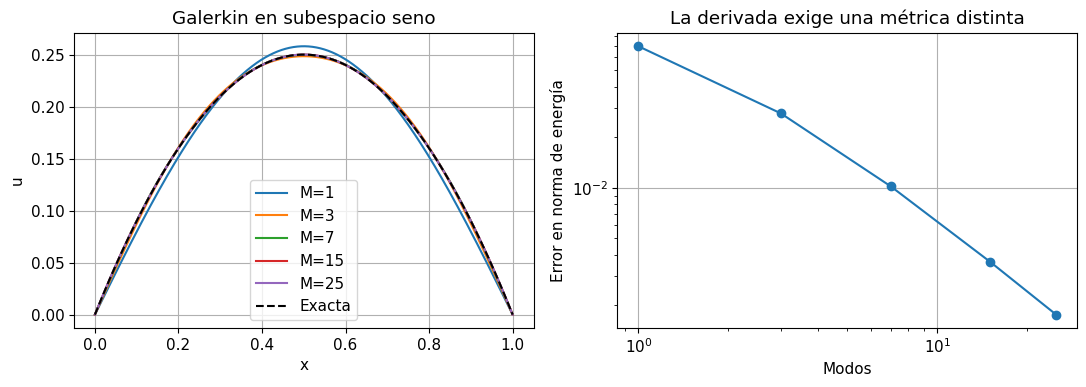

In [7]:
f_m = 2*np.sqrt(2)*(1-(-1.0)**m)/(m*np.pi)
u_m = f_m/(m*np.pi)**2
u_exact = x*(1-x)
du_exact = 1-2*x
Dphi = np.sqrt(2)*np.pi*m[None, :]*np.cos(np.pi*x[:, None]*m[None, :])
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
energy_errors = []
Ms = [1, 3, 7, 15, 25]
for M in Ms:
    uh = Phi[:, :M] @ u_m[:M]
    duh = Dphi[:, :M] @ u_m[:M]
    energy_errors.append(np.sqrt(trapezoid((duh-du_exact)**2, x)))
    axes[0].plot(x, uh, label=f"M={M}")
axes[0].plot(x, u_exact, "k--", label="Exacta")
axes[0].set(xlabel="x", ylabel="u", title="Galerkin en subespacio seno"); axes[0].legend()
axes[1].loglog(Ms, energy_errors, "o-")
axes[1].set(xlabel="Modos", ylabel="Error en norma de energía", title="La derivada exige una métrica distinta")
plt.tight_layout(); plt.show()

## 12. Operadores neuronales y espacios de funciones

Un neural operator intenta aproximar un mapa $\mathcal G:a\mapsto u$, por ejemplo coeficiente de difusión a solución. Especificar un error requiere una clase de entradas, su distribución y normas del dominio y salida. Un resultado sobre una malla no demuestra automáticamente independencia de resolución.

Las discretizaciones deben representar funciones con escalamiento consistente. Comparar en distintas mallas necesita interpolación o proyección documentada y referencia precisa. La continuidad del operador físico y regularidad de las entradas ayudan a comprender qué generalización es plausible.

| Inicio | Anterior | Siguiente |
| --- | --- | --- |
| [🏠](../README.md) | [⏪](../21_MATEMATICA_MAS_AVANZADA/21_1_Analisis_real.ipynb) | [⏩](../21_MATEMATICA_MAS_AVANZADA/21_3_PDE_avanzada.ipynb) |